# Tarefa 3 — Classificação de texto AI vs. Human com PyTorch

Este notebook implementa a Tarefa 3 com **Embeddings + BiLSTM em PyTorch**, usando o dataset `AI_Human.csv`.

- `0 = Human`;
- `1 = AI`.

Inclui divisão estratificada sem leakage, vocabulário construído apenas no treino, Embedding aprendido, BiLSTM, AdamW, regularização, gradient clipping, scheduler, early stopping, checkpoint, métricas completas, matriz de confusão e submissão externa no formato exigido.

O CSV `dataset3_inputs.csv` é usado apenas para inferência final e nunca para treino, validação ou escolha de hiperparâmetros.


In [ ]:
# 1. Imports, configuração e reprodutibilidade
import os
import re
import csv
import copy
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

SEED = 42
DATASET_PATH = Path("AI_Human.csv")
TEACHER_INPUTS = Path("dataset3_inputs.csv")
MODEL_PATH = Path("models/lstm_ai_human_best.pt")
SUBMISSION_DIR = Path("Submissao1")

GROUP_NUMBER = "7"  # substituir pelo número real do grupo
SUBMISSION_NUMBER = "3"  # Tarefa 3 / segundo modelo oficial

MAX_EXAMPLES_PER_CLASS = 25000
MAX_VOCAB_SIZE = 20000
MIN_FREQ = 2
MAX_LEN = 96
BATCH_SIZE = 128
EMBED_DIM = 64
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
EPOCHS = 6
PATIENCE = 2
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Dispositivo:", DEVICE)
print("CUDA disponível:", torch.cuda.is_available())


Dispositivo: cpu
CUDA disponível: False


## 2. Leitura, limpeza e labels

Os textos vazios são removidos. A codificação de labels é normalizada para `Human=0` e `AI=1`.


In [2]:
HUMAN_VALUES = {"0", "0.0", "false", "no", "n", "human", "humano", "real", "not generated"}
AI_VALUES = {"1", "1.0", "true", "yes", "y", "ai", "generated", "machine", "chatgpt", "gpt"}

def parse_label(value):
    value = str(value).strip().lower()
    if value in HUMAN_VALUES: return 0
    if value in AI_VALUES: return 1
    if "human" in value: return 0
    if any(term in value for term in ("ai", "gpt", "machine", "generated")): return 1
    raise ValueError(f"Rótulo não reconhecido: {value!r}")

def load_ai_human_csv(path):
    texts, labels = [], []
    with open(path, "r", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        columns = [c for c in (reader.fieldnames or []) if c]
        text_col = next((c for c in columns if c.strip().lower() in {"text", "texto", "content"}), None)
        label_col = next((c for c in columns if c.strip().lower() in {"generated", "label", "class", "target"}), None)
        if text_col is None or label_col is None:
            raise ValueError(f"Colunas encontradas: {columns}")
        for row in reader:
            text = (row.get(text_col) or "").strip()
            if text:
                texts.append(text)
                labels.append(parse_label(row.get(label_col)))
    return texts, np.asarray(labels, dtype=np.int64)

def remove_duplicates(texts, labels):
    seen = {}
    first = {}
    conflicts = set()
    for index, (text, label) in enumerate(zip(texts, labels)):
        key = " ".join(str(text).casefold().split())
        label = int(label)
        if key in seen and seen[key] != label:
            conflicts.add(key)
        else:
            seen[key] = label
            first.setdefault(key, index)
    keep = [idx for key, idx in first.items() if key not in conflicts]
    keep.sort()
    return [texts[i] for i in keep], np.asarray([labels[i] for i in keep], dtype=np.int64), len(conflicts)

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {DATASET_PATH.resolve()}")
texts, labels = load_ai_human_csv(DATASET_PATH)
texts, labels, n_conflicts = remove_duplicates(texts, labels)
print("Exemplos após limpeza:", len(texts))
print("Conflitos removidos:", n_conflicts)
print("Distribuição [Human, AI]:", np.bincount(labels, minlength=2))


Exemplos após limpeza: 464223
Conflitos removidos: 5
Distribuição [Human, AI]: [284462 179761]


## 3. Amostragem equilibrada e divisão estratificada

A amostragem limita o custo computacional e mantém o mesmo número máximo de exemplos por classe. A divisão é feita depois da amostragem e é estratificada.


In [3]:
def limit_per_class(texts, labels, max_per_class, seed=SEED):
    rng = np.random.RandomState(seed)
    texts = np.asarray(texts, dtype=object)
    labels = np.asarray(labels, dtype=np.int64)
    selected = []
    for cls in np.unique(labels):
        indices = np.where(labels == cls)[0]
        rng.shuffle(indices)
        selected.extend(indices[:max_per_class])
    rng.shuffle(selected)
    selected = np.asarray(selected, dtype=np.int64)
    return texts[selected].tolist(), labels[selected]

def stratified_split(texts, labels, train_frac=0.70, val_frac=0.15, seed=SEED):
    rng = np.random.RandomState(seed)
    texts = np.asarray(texts, dtype=object)
    labels = np.asarray(labels, dtype=np.int64)
    train_idx, val_idx, test_idx = [], [], []
    for cls in np.unique(labels):
        cls_idx = np.where(labels == cls)[0]
        rng.shuffle(cls_idx)
        n = len(cls_idx)
        n_train, n_val = int(n * train_frac), int(n * val_frac)
        train_idx.extend(cls_idx[:n_train])
        val_idx.extend(cls_idx[n_train:n_train+n_val])
        test_idx.extend(cls_idx[n_train+n_val:])
    for indices in (train_idx, val_idx, test_idx): rng.shuffle(indices)
    return (texts[train_idx].tolist(), labels[train_idx], texts[val_idx].tolist(), labels[val_idx], texts[test_idx].tolist(), labels[test_idx])

texts, labels = limit_per_class(texts, labels, MAX_EXAMPLES_PER_CLASS)
texts_train, y_train, texts_val, y_val, texts_test, y_test = stratified_split(texts, labels)
for name, y in (("treino", y_train), ("validação", y_val), ("teste", y_test)):
    print(f"{name:10s}: {len(y):,} | [Human, AI] = {np.bincount(y, minlength=2)}")


treino    : 35,000 | [Human, AI] = [17500 17500]
validação : 7,500 | [Human, AI] = [3750 3750]
teste     : 7,500 | [Human, AI] = [3750 3750]


## 4. Tokenização, vocabulário e DataLoaders

O vocabulário é criado apenas com `texts_train`. Os embeddings não são pré-treinados: são aprendidos durante o treino da BiLSTM.


In [4]:
TOKEN_RE = re.compile(r"[a-zA-Z]+(?:'[a-zA-Z]+)?|[0-9]+|[^\W_]+", re.UNICODE)
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"

def tokenize(text):
    return TOKEN_RE.findall(str(text).lower())

def build_vocab(train_texts, max_size=MAX_VOCAB_SIZE, min_freq=MIN_FREQ):
    counter = Counter()
    for text in train_texts: counter.update(tokenize(text))
    itos = [PAD_TOKEN, UNK_TOKEN]
    itos.extend(token for token, freq in counter.most_common() if freq >= min_freq and token not in itos)
    itos = itos[:max_size]
    return {token: i for i, token in enumerate(itos)}, itos

stoi, itos = build_vocab(texts_train)
PAD_IDX, UNK_IDX = stoi[PAD_TOKEN], stoi[UNK_TOKEN]
print("Vocabulário:", len(itos), "| PAD:", PAD_IDX, "| UNK:", UNK_IDX)

class AIHumanDataset(Dataset):
    def __init__(self, texts, labels, stoi, max_len=MAX_LEN):
        self.texts, self.labels, self.stoi, self.max_len = texts, np.asarray(labels, dtype=np.int64), stoi, max_len
    def __len__(self): return len(self.labels)
    def __getitem__(self, index):
        ids = [self.stoi.get(token, UNK_IDX) for token in tokenize(self.texts[index])[:self.max_len]] or [UNK_IDX]
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[index], dtype=torch.long)

def collate_batch(batch):
    sequences, labels_batch = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.stack(labels_batch)

train_loader = DataLoader(AIHumanDataset(texts_train, y_train, stoi), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, num_workers=NUM_WORKERS)
val_loader = DataLoader(AIHumanDataset(texts_val, y_val, stoi), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, num_workers=NUM_WORKERS)
test_loader = DataLoader(AIHumanDataset(texts_test, y_test, stoi), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch, num_workers=NUM_WORKERS)


Vocabulário: 20000 | PAD: 0 | UNK: 1


## 5. Modelo Embedding + BiLSTM

A sequência é empacotada com `pack_padded_sequence`, evitando que o padding seja tratado como texto. O estado final das duas direcções da LSTM é concatenado para a classificação.


In [5]:
class LSTMTextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size, num_layers, dropout, pad_idx, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_size, num_layers=num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * 2, num_classes)
    def forward(self, input_ids, lengths):
        embedded = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.classifier(self.dropout(representation))

model = LSTMTextClassifier(len(stoi), EMBED_DIM, HIDDEN_SIZE, NUM_LAYERS, DROPOUT, PAD_IDX).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)
print(model)
print("Parâmetros treináveis:", sum(p.numel() for p in model.parameters() if p.requires_grad))


LSTMTextClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)
Parâmetros treináveis: 1346818


## 6. Métricas e funções de treino

In [6]:
def binary_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=np.int64), np.asarray(y_pred, dtype=np.int64)
    result, f1_values = {}, []
    for cls, name in ((0, "human"), (1, "ai")):
        tp = int(np.sum((y_true == cls) & (y_pred == cls)))
        fp = int(np.sum((y_true != cls) & (y_pred == cls)))
        fn = int(np.sum((y_true == cls) & (y_pred != cls)))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        result[f"precision_{name}"], result[f"recall_{name}"], result[f"f1_{name}"] = precision, recall, f1
        f1_values.append(f1)
    result["accuracy"] = float(np.mean(y_true == y_pred))
    result["macro_f1"] = float(np.mean(f1_values))
    result["confusion_matrix"] = np.array([[np.sum((y_true==0)&(y_pred==0)), np.sum((y_true==0)&(y_pred==1))], [np.sum((y_true==1)&(y_pred==0)), np.sum((y_true==1)&(y_pred==1))]], dtype=np.int64)
    return result

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_items, all_targets, all_preds = 0.0, 0, [], []
    for input_ids, lengths, targets in loader:
        input_ids, lengths, targets = input_ids.to(DEVICE), lengths.to(DEVICE), targets.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids, lengths)
        loss = criterion(logits, targets)
        if training:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item() * targets.size(0)
        total_items += targets.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
    metrics = binary_metrics(all_targets, all_preds)
    metrics["loss"] = total_loss / max(total_items, 1)
    return metrics


## 7. Treino com early stopping e checkpoint

A escolha do melhor modelo é feita apenas pela perda de validação. O conjunto de teste permanece intocado até à avaliação final.


In [7]:
history = {"train_loss": [], "val_loss": [], "train_macro_f1": [], "val_macro_f1": [], "train_accuracy": [], "val_accuracy": [], "lr": []}
best_val_loss, best_state, bad_epochs = float("inf"), None, 0
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    val_metrics = run_epoch(model, val_loader, criterion)
    scheduler.step(val_metrics["loss"])
    current_lr = optimizer.param_groups[0]["lr"]
    for key, value in (("train_loss", train_metrics["loss"]), ("val_loss", val_metrics["loss"]), ("train_macro_f1", train_metrics["macro_f1"]), ("val_macro_f1", val_metrics["macro_f1"]), ("train_accuracy", train_metrics["accuracy"]), ("val_accuracy", val_metrics["accuracy"]), ("lr", current_lr)):
        history[key].append(value)
    print(f"Epoch {epoch:02d}/{EPOCHS} | lr={current_lr:.2e} | train_loss={train_metrics['loss']:.4f} | val_loss={val_metrics['loss']:.4f} | train_macro_f1={train_metrics['macro_f1']:.4f} | val_macro_f1={val_metrics['macro_f1']:.4f}")
    if val_metrics["loss"] < best_val_loss - 1e-4:
        best_val_loss = val_metrics["loss"]
        best_state = copy.deepcopy(model.state_dict())
        bad_epochs = 0
        checkpoint = {"model_state_dict": best_state, "stoi": stoi, "itos": itos, "config": {"embed_dim": EMBED_DIM, "hidden_size": HIDDEN_SIZE, "num_layers": NUM_LAYERS, "dropout": DROPOUT, "max_len": MAX_LEN, "pad_idx": PAD_IDX, "vocab_size": len(stoi), "seed": SEED, "label_definition": {"0": "Human", "1": "AI"}}}
        torch.save(checkpoint, MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping ativado.")
            break

if best_state is not None: model.load_state_dict(best_state)
print("Melhor modelo guardado em:", MODEL_PATH.resolve())


Epoch 01/6 | lr=1.00e-03 | train_loss=0.4309 | val_loss=0.3417 | train_macro_f1=0.7839 | val_macro_f1=0.8709
Epoch 02/6 | lr=1.00e-03 | train_loss=0.1896 | val_loss=0.2657 | train_macro_f1=0.9283 | val_macro_f1=0.9240
Epoch 03/6 | lr=1.00e-03 | train_loss=0.1292 | val_loss=0.2895 | train_macro_f1=0.9531 | val_macro_f1=0.9301
Epoch 04/6 | lr=1.00e-03 | train_loss=0.1074 | val_loss=0.2127 | train_macro_f1=0.9606 | val_macro_f1=0.9425
Epoch 05/6 | lr=1.00e-03 | train_loss=0.0843 | val_loss=0.1903 | train_macro_f1=0.9693 | val_macro_f1=0.9464
Epoch 06/6 | lr=1.00e-03 | train_loss=0.0746 | val_loss=0.1989 | train_macro_f1=0.9737 | val_macro_f1=0.9546
Melhor modelo guardado em: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\models\lstm_ai_human_best.pt


## 8. Curvas de aprendizagem e avaliação final no teste

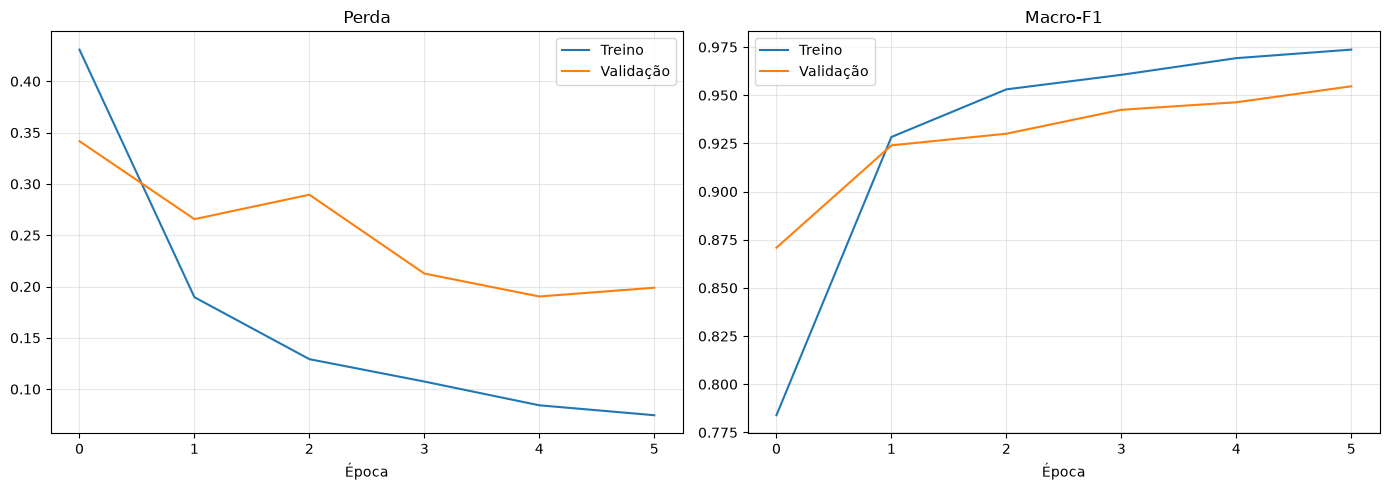

=== RESULTADOS FINAIS — TESTE ===
Loss: 0.2000 | Accuracy: 0.9464 | Macro-F1: 0.9463
human: precision=0.9172 | recall=0.9813 | f1=0.9482
ai: precision=0.9799 | recall=0.9115 | f1=0.9445
Matriz de confusão [linhas=real, colunas=previsto]:
[[3680   70]
 [ 332 3418]]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history["train_loss"], label="Treino")
axes[0].plot(history["val_loss"], label="Validação")
axes[0].set_title("Perda")
axes[0].set_xlabel("Época")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history["train_macro_f1"], label="Treino")
axes[1].plot(history["val_macro_f1"], label="Validação")
axes[1].set_title("Macro-F1")
axes[1].set_xlabel("Época")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

test_metrics = run_epoch(model, test_loader, criterion)
print("=== RESULTADOS FINAIS — TESTE ===")
print(f"Loss: {test_metrics['loss']:.4f} | Accuracy: {test_metrics['accuracy']:.4f} | Macro-F1: {test_metrics['macro_f1']:.4f}")
for name in ("human", "ai"):
    print(f"{name}: precision={test_metrics['precision_'+name]:.4f} | recall={test_metrics['recall_'+name]:.4f} | f1={test_metrics['f1_'+name]:.4f}")
print("Matriz de confusão [linhas=real, colunas=previsto]:")
print(test_metrics["confusion_matrix"])


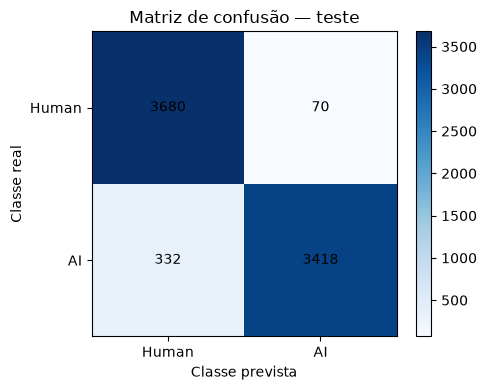

In [9]:
cm = test_metrics["confusion_matrix"]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["Human", "AI"]); ax.set_yticks([0, 1], labels=["Human", "AI"])
ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real"); ax.set_title("Matriz de confusão — teste")
for i in range(2):
    for j in range(2): ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


## 9. Inferência no dataset do professor e submissão `s2`

O ficheiro é validado, classificado pela BiLSTM e exportado com as colunas `ID`, `Text` e `output`. Não existem métricas calculáveis porque os labels do professor não são fornecidos.


In [10]:
def predict_texts(model, new_texts):
    model.eval()
    encoded = []
    for text in new_texts:
        ids = [stoi.get(token, UNK_IDX) for token in tokenize(text)[:MAX_LEN]] or [UNK_IDX]
        encoded.append(torch.tensor(ids, dtype=torch.long))
    lengths = torch.tensor([len(item) for item in encoded], dtype=torch.long)
    batch = pad_sequence(encoded, batch_first=True, padding_value=PAD_IDX).to(DEVICE)
    with torch.no_grad():
        probabilities = torch.softmax(model(batch, lengths.to(DEVICE)), dim=1)[:, 1]
    return [("AI" if float(probability) >= 0.5 else "Human", float(probability)) for probability in probabilities]

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
if not TEACHER_INPUTS.exists():
    print(f"{TEACHER_INPUTS.resolve()} não encontrado; submissão não gerada.")
else:
    teacher_df = pd.read_csv(TEACHER_INPUTS, sep=";", encoding="utf-8-sig")
    if len(teacher_df) != 100: raise ValueError(f"Esperavam-se 100 exemplos, encontrados {len(teacher_df)}")
    if list(teacher_df.columns) != ["ID", "Text"]: raise ValueError(f"Colunas inesperadas: {list(teacher_df.columns)}")
    if teacher_df["ID"].duplicated().any(): raise ValueError("IDs duplicados nos inputs do professor.")
    if teacher_df["Text"].isna().any() or teacher_df["Text"].astype(str).str.strip().eq("").any(): raise ValueError("Textos vazios nos inputs do professor.")
    predictions = predict_texts(model, teacher_df["Text"].astype(str).tolist())
    submission_df = teacher_df.copy()
    submission_df["output"] = [label for label, probability in predictions]
    submission_path = SUBMISSION_DIR / f"submissao1-grupo{GROUP_NUMBER}-s{SUBMISSION_NUMBER}.csv"
    submission_df.to_csv(submission_path, sep=";", index=False, encoding="utf-8")
    print("Submissão PyTorch criada:", submission_path.resolve())
    print("Distribuição:", submission_df["output"].value_counts().to_dict())


Submissão PyTorch criada: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1\submissao1-grupo3-s2.csv
Distribuição: {'AI': 64, 'Human': 36}


In [11]:
# 10. Validação final do CSV e gravação do relatório de resultados
if TEACHER_INPUTS.exists():
    saved = pd.read_csv(submission_path, sep=";", encoding="utf-8-sig")
    assert len(saved) == 100
    assert list(saved.columns) == ["ID", "Text", "output"]
    assert saved["ID"].is_unique
    assert set(saved["output"]).issubset({"Human", "AI"})
    print("FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO")

results = {
    "task": "Tarefa 3",
    "model": "Embedding + BiLSTM PyTorch",
    "device": str(DEVICE),
    "train_size": len(y_train), "validation_size": len(y_val), "test_size": len(y_test),
    "vocab_size": len(stoi), "max_len": MAX_LEN,
    "test_loss": float(test_metrics["loss"]), "test_accuracy": float(test_metrics["accuracy"]), "test_macro_f1": float(test_metrics["macro_f1"]),
    "test_confusion_matrix": test_metrics["confusion_matrix"].tolist(),
    "checkpoint": str(MODEL_PATH)
}
Path("models").mkdir(exist_ok=True)
with open("models/tarefa3_results.json", "w", encoding="utf-8") as file:
    json.dump(results, file, indent=2, ensure_ascii=False)
print(json.dumps(results, indent=2, ensure_ascii=False))


FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO
{
  "task": "Tarefa 3",
  "model": "Embedding + BiLSTM PyTorch",
  "device": "cpu",
  "train_size": 35000,
  "validation_size": 7500,
  "test_size": 7500,
  "vocab_size": 20000,
  "max_len": 96,
  "test_loss": 0.20001788521607716,
  "test_accuracy": 0.9464,
  "test_macro_f1": 0.9463345099751598,
  "test_confusion_matrix": [
    [
      3680,
      70
    ],
    [
      332,
      3418
    ]
  ],
  "checkpoint": "models\\lstm_ai_human_best.pt"
}


## Checklist final da Tarefa 3

- [x] Dataset `AI_Human.csv`, não `AG_NEWS`.
- [x] Split treino/validação/teste estratificado.
- [x] Vocabulário construído apenas no treino.
- [x] Embeddings aprendidos no PyTorch.
- [x] BiLSTM com `pack_padded_sequence`.
- [x] Dropout, AdamW, weight decay e gradient clipping.
- [x] Scheduler e early stopping.
- [x] Checkpoint com pesos, `stoi`, `itos` e configuração.
- [x] Accuracy, Precision, Recall, F1, Macro-F1 e matriz de confusão.
- [x] CSV externo validado e exportado como `s2`.

O ficheiro produzido por esta tarefa é o segundo modelo oficial, por exemplo `submissao1-grupo3-s2.csv`. O primeiro deve ser o CSV da DNN NumPy da Tarefa 2 (`s1`).
